## Trabajo Práctico 3 – Aprendizaje No Supervisado
### Dataset: Palmer Penguins
### **Realizado por**: Jose Daniel Cabarcas Mass

#### Cargar librerias 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

#### Dataset
Se utiliza el conjunto de datos Palmer Penguins, disponible públicamente en GitHub. Este dataset contiene información sobre diferentes características físicas de tres especies de pingüinos observados en el archipiélago Palmer, en la Antártida.

Inicialmente, se realiza una exploración general para identificar la cantidad de registros, las variables disponibles y los tipos de datos que contiene el conjunto de informació

In [3]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

display(df.head())

print("Dimensiones del dataset:", df.shape)

df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Dimensiones del dataset: (344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


#### Selección y limpieza de variables
Para el desarrollo del análisis se seleccionan cuatro variables numéricas relacionadas con las características físicas de los pingüinos: longitud del pico, profundidad del pico, longitud de las aletas y masa corporal.

Estas características permiten estudiar las diferencias físicas entre los individuos y explorar posibles agrupamientos naturales.

Se eliminan los registros que presentan valores faltantes en las variables seleccionadas, con el propósito de trabajar con información completa.

In [4]:
variables = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

df_analisis = df[variables].dropna().copy()

print("Dimensiones del dataset limpio:", df_analisis.shape)

print("\nValores faltantes:")
print(df_analisis.isnull().sum())


display(df_analisis.head())

Dimensiones del dataset limpio: (342, 4)

Valores faltantes:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


#### Análisis descriptivo
Se realiza un análisis estadístico descriptivo para conocer el comportamiento de las variables seleccionadas. Se examinan medidas como la media, desviación estándar, valores mínimos, máximos y cuartiles.

Esta información permite comprender las características generales de los datos antes de aplicar los procedimientos de reducción de dimensionalidad y agrupamiento.

In [5]:
display(df_analisis.describe().T)

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


#### Estandarización de los datos
Debido a que las variables seleccionadas presentan diferentes unidades de medida y escalas numéricas, es necesario realizar un proceso de estandarización mediante StandardScaler.

Este procedimiento transforma las variables para que tengan una media cercana a cero y una desviación estándar cercana a uno. La estandarización es importante porque PCA y K-means pueden verse afectados por las diferencias de escala entre las variables.

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_analisis)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables,
    index=df_analisis.index
)

display(X_scaled.head())

print("Media de las variables:")
print(X_scaled.mean().round(4))

print("\nDesviación estándar:")
print(X_scaled.std().round(4))

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
4,-1.324737,1.089724,-0.563715,-0.938776
5,-0.847812,1.748985,-0.777373,-0.689020


Media de las variables:
bill_length_mm       0.0
bill_depth_mm        0.0
flipper_length_mm   -0.0
body_mass_g          0.0
dtype: float64

Desviación estándar:
bill_length_mm       1.0015
bill_depth_mm        1.0015
flipper_length_mm    1.0015
body_mass_g          1.0015
dtype: float64


#### Reducción de dimensionalidad mediante PCA
El Análisis de Componentes Principales (PCA) es una técnica que permite reducir la cantidad de variables de un conjunto de datos mediante la creación de nuevas dimensiones denominadas componentes principales.

Estas componentes resumen la información de las variables originales, procurando conservar la mayor cantidad posible de variabilidad.

En esta etapa se aplica PCA sobre las cuatro variables estandarizadas para identificar cuánta información puede concentrarse en un número menor de componentes.

In [7]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

varianza_explicada = pca.explained_variance_ratio_ * 100

resultados_pca = pd.DataFrame({
    'Componente': [
        f'PC{i+1}' for i in range(len(varianza_explicada))
    ],
    'Varianza explicada (%)': varianza_explicada,
    'Varianza acumulada (%)': np.cumsum(varianza_explicada)
})

display(resultados_pca.round(2))

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,68.84,68.84
1,PC2,19.31,88.16
2,PC3,9.13,97.29
3,PC4,2.71,100.00


#### Scree Plot y varianza explicada
Se construye el gráfico Scree Plot para visualizar el porcentaje de varianza explicado por cada componente principal.

Esta representación permite identificar cuáles componentes concentran una mayor proporción de información y determinar si es conveniente reducir las cuatro variables originales a dos componentes.

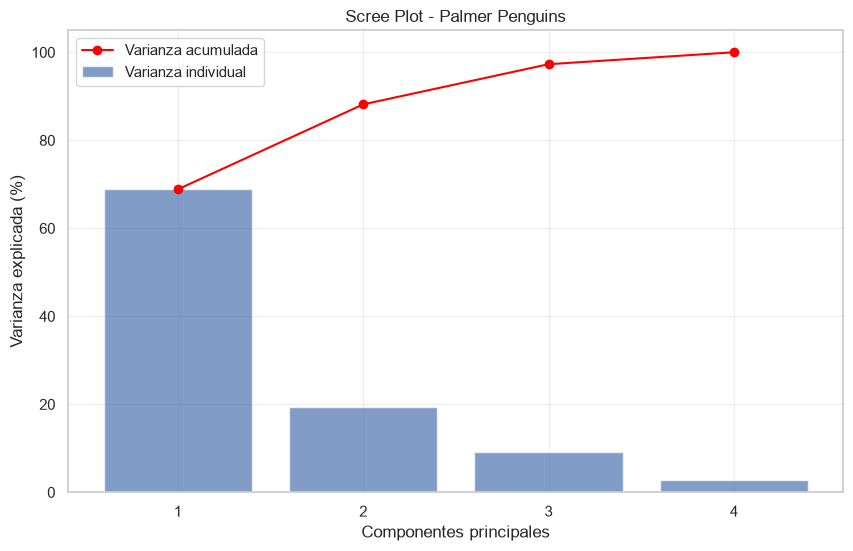

In [8]:
componentes = range(1, len(varianza_explicada) + 1)

plt.figure(figsize=(10, 6))

plt.bar(
    componentes,
    varianza_explicada,
    alpha=0.7,
    label='Varianza individual'
)

plt.plot(
    componentes,
    np.cumsum(varianza_explicada),
    marker='o',
    color='red',
    label='Varianza acumulada'
)

plt.xlabel('Componentes principales')
plt.ylabel('Varianza explicada (%)')
plt.title('Scree Plot - Palmer Penguins')
plt.xticks(list(componentes))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

El gráfico permite observar cómo se distribuye la información entre las diferentes componentes principales. Se prestará especial atención a las dos primeras componentes, ya que serán utilizadas para representar los datos en dos dimensiones.

La varianza acumulada permitirá evaluar qué proporción de la información original se conserva al reducir las cuatro variables a dos componentes.

#### Reducción a dos componentes principales

Se reduce el conjunto de datos a las dos primeras componentes principales (PC1 y PC2). Esta transformación permite representar las cuatro variables originales mediante dos nuevas dimensiones, facilitando la visualización de los datos y el análisis de posibles agrupamientos.

In [9]:
pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    X_pca_2,
    columns=['PC1', 'PC2'],
    index=df_analisis.index
)

display(df_pca.head())

varianza_2_componentes = (
    pca_2.explained_variance_ratio_.sum() * 100
)

print(
    f"Varianza explicada por las dos componentes: "
    f"{varianza_2_componentes:.2f}%"
)

,PC1,PC2
0,-1.843445,0.047702
1,-1.306762,-0.428348
2,-1.369181,-0.154476
4,-1.878827,-0.002048
5,-1.911748,0.829210


Varianza explicada por las dos componentes: 88.16%


#### Visualización de las componentes principales
Se realiza un diagrama de dispersión utilizando las dos componentes principales obtenidas mediante PCA.

Para facilitar la interpretación, se utilizará la especie de cada pingüino como referencia visual, sin incorporarla al proceso de entrenamiento.

Esto permitirá observar si las características físicas seleccionadas presentan patrones diferenciados entre las especies y si existen zonas de superposición.

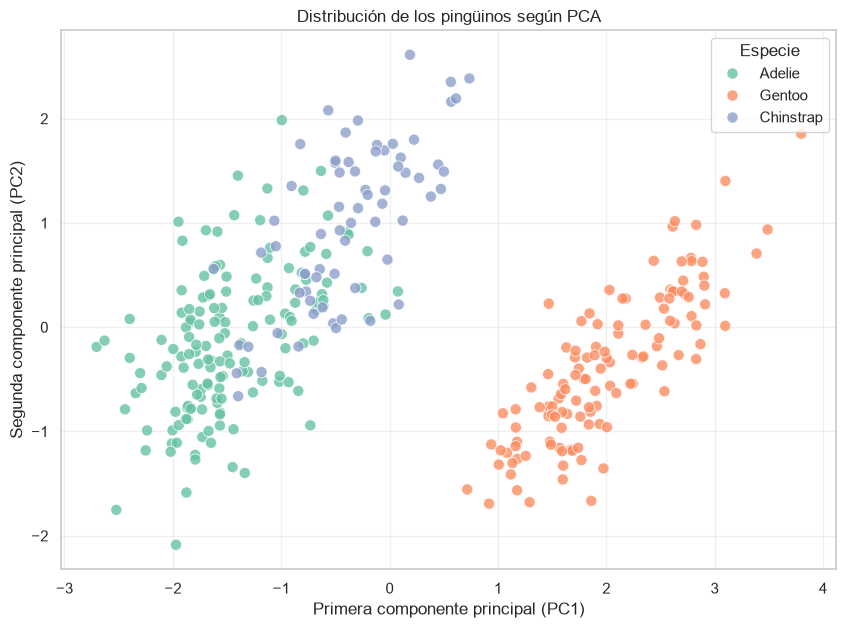

In [10]:
df_grafico_pca = df_pca.copy()

df_grafico_pca['species'] = df.loc[
    df_analisis.index, 'species'
]

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_grafico_pca,
    x='PC1',
    y='PC2',
    hue='species',
    palette='Set2',
    s=65,
    alpha=0.8
)

plt.title('Distribución de los pingüinos según PCA')
plt.xlabel('Primera componente principal (PC1)')
plt.ylabel('Segunda componente principal (PC2)')
plt.legend(title='Especie')
plt.grid(alpha=0.3)

plt.show()

El gráfico permite analizar la distribución de los pingüinos en el espacio de las dos componentes principales.

Se observará si existen grupos diferenciados, concentraciones de individuos o zonas de superposición. La comparación visual con las especies conocidas permitirá evaluar si las características físicas contienen información suficiente para distinguir patrones entre los individuos.

#### Selección de variables
Se calcula la matriz de correlación de Pearson para identificar posibles relaciones lineales entre las cuatro variables originales.

El objetivo es determinar si algunas características físicas presentan información redundante. Se utilizará como referencia un umbral de correlación absoluta superior a 0.80 para identificar relaciones elevadas entre variables.

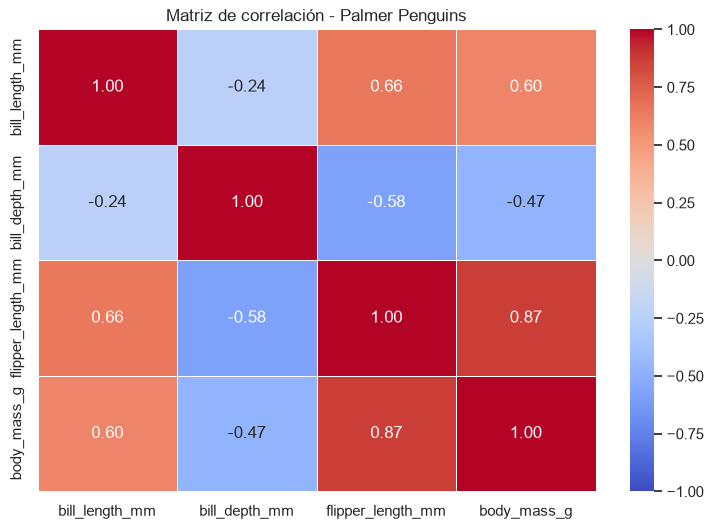

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


In [11]:
matriz_correlacion = df_analisis.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación - Palmer Penguins')

plt.show()

display(matriz_correlacion.round(3))

La matriz de correlación permite identificar la intensidad y dirección de las relaciones entre las características físicas de los pingüinos.

Los valores cercanos a +1 indican una relación positiva fuerte, mientras que los valores cercanos a -1 representan una relación negativa fuerte.

A partir de estos resultados se identificarán las variables que presentan mayor redundancia y se establecerá cuáles características se conservarán para el siguiente escenario de agrupamiento.

#### Selección de variables
A partir de la matriz de correlación, se realizará la selección de variables utilizando el umbral de 0.80.

Se conservarán las características que aporten información complementaria y se evitará mantener simultáneamente variables que presenten una correlación absoluta igual o superior al umbral establecido.

In [12]:
umbral = 0.80

correlacion_abs = matriz_correlacion.abs()

promedio_correlacion = (
    correlacion_abs.sum() - 1
) / (len(correlacion_abs) - 1)

variables_ordenadas = promedio_correlacion.sort_values(
    ascending=False
).index.tolist()

variables_seleccionadas = []

for variable in variables_ordenadas:

    if all(
        correlacion_abs.loc[variable, seleccionada] < umbral
        for seleccionada in variables_seleccionadas
    ):
        variables_seleccionadas.append(variable)

df_seleccion = df_analisis[
    variables_seleccionadas
].copy()

print("Variables originales:", len(variables))

print("Variables seleccionadas:", len(variables_seleccionadas))

print("\nVariables conservadas:")
print(variables_seleccionadas)

print("\nDimensiones del dataset reducido:")
print(df_seleccion.shape)

display(df_seleccion.head())

Variables originales: 4
Variables seleccionadas: 3

Variables conservadas:
['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']

Dimensiones del dataset reducido:
(342, 3)


,flipper_length_mm,bill_length_mm,bill_depth_mm
0,181.0,39.1,18.7
1,186.0,39.5,17.4
2,195.0,40.3,18.0
4,193.0,36.7,19.3
5,190.0,39.3,20.6


El procedimiento permite obtener un conjunto reducido de variables, evitando conservar características que presentan una correlación absoluta igual o superior al umbral establecido.

La cantidad y los nombres de las variables conservadas permitirán evaluar qué características físicas aportan información complementaria para el análisis.

#### Estandarización de las variables seleccionadas
Después de seleccionar las variables, se realiza nuevamente el proceso de estandarización mediante StandardScaler.

Esto permite garantizar que todas las características tengan una escala comparable antes de aplicar K-means, evitando que las diferencias en sus unidades de medida condicionen excesivamente la formación de los grupos.

In [13]:
scaler_seleccion = StandardScaler()

X_seleccion = scaler_seleccion.fit_transform(
    df_seleccion
)

X_seleccion = pd.DataFrame(
    X_seleccion,
    columns=variables_seleccionadas,
    index=df_seleccion.index
)

display(X_seleccion.head())

print("Media de las variables:")
print(X_seleccion.mean().round(4))

print("\nDesviación estándar:")
print(X_seleccion.std().round(4))

,flipper_length_mm,bill_length_mm,bill_depth_mm
0,-1.418347,-0.884499,0.785449
1,-1.062250,-0.811126,0.126188
2,-0.421277,-0.664380,0.430462
4,-0.563715,-1.324737,1.089724
5,-0.777373,-0.847812,1.748985


Media de las variables:
flipper_length_mm   -0.0
bill_length_mm       0.0
bill_depth_mm        0.0
dtype: float64

Desviación estándar:
flipper_length_mm    1.0015
bill_length_mm       1.0015
bill_depth_mm        1.0015
dtype: float64


### Agrupamiento y comparación de resultados
Se aplica el algoritmo K-means sobre las tres versiones del conjunto de datos: original, reducido mediante PCA y resultante de la selección de variables.

Se evaluarán diferentes cantidades de agrupamientos, utilizando valores de K entre 2 y 6.

Para evaluar la calidad de los resultados se utilizarán dos métricas: la inercia y el coeficiente Silhouette. Esto permitirá comparar la cohesión interna de los grupos y su separación respecto a los demás

In [14]:
conjuntos_datos = {
    'Original': X_scaled,
    'PCA': df_pca,
    'Selección de variables': X_seleccion
}

resultados_kmeans = []

modelos_kmeans = {}

for nombre, datos in conjuntos_datos.items():

    modelos_kmeans[nombre] = {}

    for k in range(2, 7):

        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        etiquetas = modelo.fit_predict(datos)

        inercia = modelo.inertia_

        silhouette = silhouette_score(
            datos,
            etiquetas
        )

        modelos_kmeans[nombre][k] = modelo

        resultados_kmeans.append({
            'Enfoque': nombre,
            'K': k,
            'Inercia': inercia,
            'Silhouette Score': silhouette
        })

df_resultados = pd.DataFrame(resultados_kmeans)

display(df_resultados.round(4))

,Enfoque,K,Inercia,Silhouette Score
0,Original,2,565.7076,0.5315
1,Original,3,379.3925,0.4472
2,Original,4,300.3995,0.3996
3,Original,5,232.6049,0.3789
4,Original,6,204.3926,0.3680
5,PCA,2,403.9549,0.6119
6,PCA,3,228.3301,0.5391
7,PCA,4,157.7261,0.5064
8,PCA,5,114.5069,0.4665
9,PCA,6,97.2234,0.4436


La tabla permite observar el desempeño del algoritmo K-means para cada enfoque y número de agrupamientos.

La inercia mide la distancia interna de los grupos, mientras que Silhouette evalúa su cohesión y separación.

Un Silhouette Score más cercano a 1 representa una mejor separación entre los grupos. Los valores cercanos a cero indican superposición, mientras que los negativos pueden señalar asignaciones inadecuadas.

#### Método del codo (Elbow Method)
Se utiliza el método del codo para identificar un posible número adecuado de agrupamientos. Esta técnica analiza cómo disminuye la inercia al incrementar el valor de K.

El punto en el que la reducción de la inercia comienza a ser menos pronunciada se conoce como el codo y permite establecer una referencia para seleccionar la cantidad de grupos.

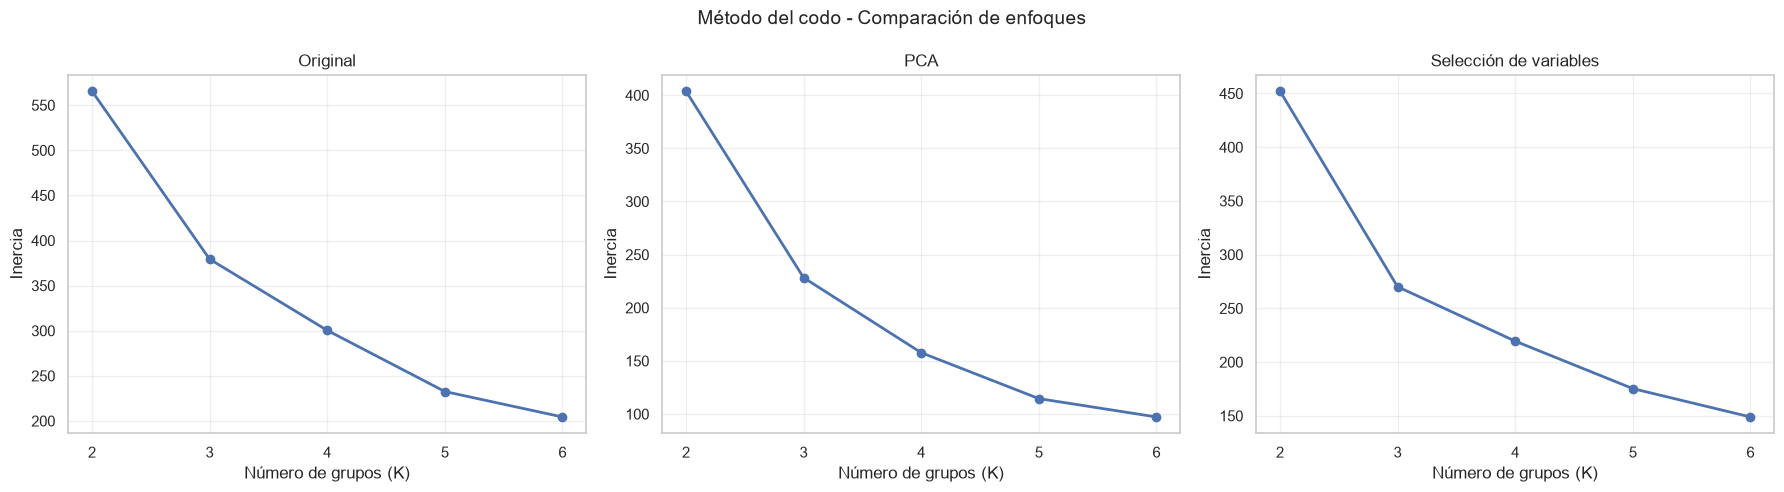

In [15]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (nombre, grupo) in zip(
    axes,
    df_resultados.groupby('Enfoque')
):

    ax.plot(
        grupo['K'],
        grupo['Inercia'],
        marker='o',
        linewidth=2
    )

    ax.set_title(nombre)
    ax.set_xlabel('Número de grupos (K)')
    ax.set_ylabel('Inercia')
    ax.set_xticks(range(2, 7))
    ax.grid(alpha=0.3)

plt.suptitle(
    'Método del codo - Comparación de enfoques',
    fontsize=14
)

plt.tight_layout()
plt.show()

Los gráficos permiten comparar el comportamiento de la inercia en los tres enfoques.

Se buscará identificar el punto en el que agregar nuevos agrupamientos deja de generar reducciones importantes en la inercia.

Esta comparación permitirá evaluar si PCA y la selección de variables modifican la estructura de los agrupamientos respecto al conjunto original.

#### Evaluación mediante Silhouette Score
Se utiliza el coeficiente Silhouette para evaluar la calidad de los agrupamientos obtenidos mediante K-means.

Esta métrica permite determinar qué tan similares son las observaciones dentro de un mismo grupo y qué tan diferentes son respecto a los demás grupos.

Se compararán los resultados para identificar cuál enfoque presenta una estructura de agrupamiento más definida.

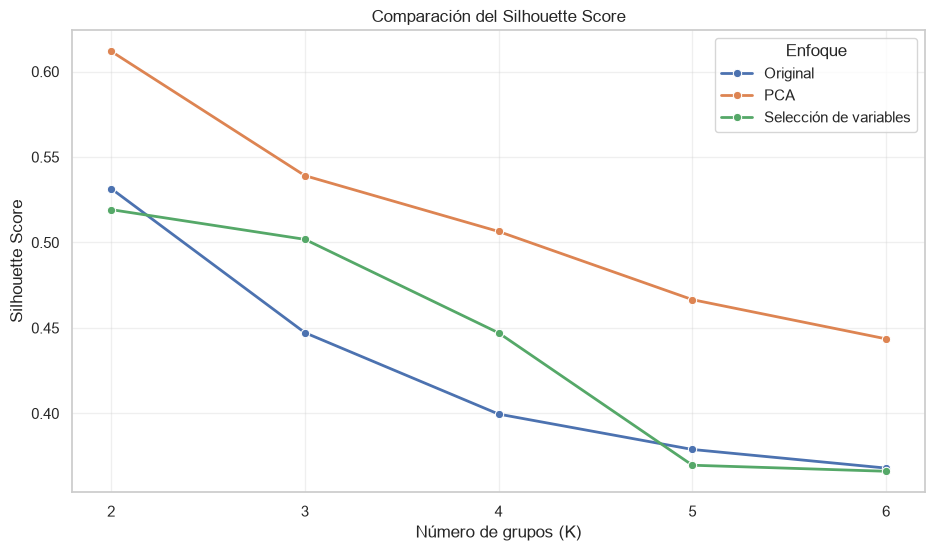

In [16]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=df_resultados,
    x='K',
    y='Silhouette Score',
    hue='Enfoque',
    marker='o',
    linewidth=2
)

plt.title('Comparación del Silhouette Score')
plt.xlabel('Número de grupos (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.legend(title='Enfoque')

plt.show()

### Tabla comparativa de resultados 

Se consolidan los resultados obtenidos mediante K-means para facilitar la comparación de los tres enfoques.

Se presentan las métricas de inercia y Silhouette Score para cada valor de K, permitiendo identificar las configuraciones con mejores resultados.

In [17]:
tabla_comparativa = df_resultados.pivot(
    index='K',
    columns='Enfoque',
    values='Silhouette Score'
)

print("COMPARACIÓN DE SILHOUETTE SCORE")

display(tabla_comparativa.round(4))

mejor_resultado = df_resultados.loc[
    df_resultados['Silhouette Score'].idxmax()
]

print("\nMejor configuración encontrada:")

print("Enfoque:", mejor_resultado['Enfoque'])
print("Número de grupos:", mejor_resultado['K'])

print(
    "Silhouette Score:",
    round(mejor_resultado['Silhouette Score'], 4)
)

tabla_inercia = df_resultados.pivot(
    index='K',
    columns='Enfoque',
    values='Inercia'
)

print("\nCOMPARACIÓN DE INERCIA")

display(tabla_inercia.round(2))

COMPARACIÓN DE SILHOUETTE SCORE


Enfoque,Original,PCA,Selección de variables
K,,,
2,0.5315,0.6119,0.5192
3,0.4472,0.5391,0.5018
4,0.3996,0.5064,0.4471
5,0.3789,0.4665,0.3697
6,0.3680,0.4436,0.3661



Mejor configuración encontrada:
Enfoque: PCA
Número de grupos: 2
Silhouette Score: 0.6119

COMPARACIÓN DE INERCIA


Enfoque,Original,PCA,Selección de variables
K,,,
2,565.71,403.95,452.28
3,379.39,228.33,270.15
4,300.40,157.73,219.47
5,232.60,114.51,175.30
6,204.39,97.22,148.89


La tabla permite identificar las diferencias en la calidad de los agrupamientos obtenidos mediante los tres enfoques.

Se prestará especial atención a la configuración que presente el mayor coeficiente Silhouette y a los puntos de inflexión identificados mediante el método del codo.

La comparación permitirá determinar si trabajar con las variables originales, reducir la dimensionalidad mediante PCA o seleccionar características específicas permite obtener agrupamientos más definidos.

#### Interpretación final de los agrupamientos
Se representarán gráficamente los agrupamientos obtenidos mediante K-means para los tres enfoques.

Para garantizar una comparación visual adecuada, se utilizará la configuración con mejor Silhouette Score de cada enfoque. En el caso del conjunto original y el conjunto seleccionado, se utilizará PCA únicamente como herramienta de visualización, sin modificar las etiquetas obtenidas por K-means.

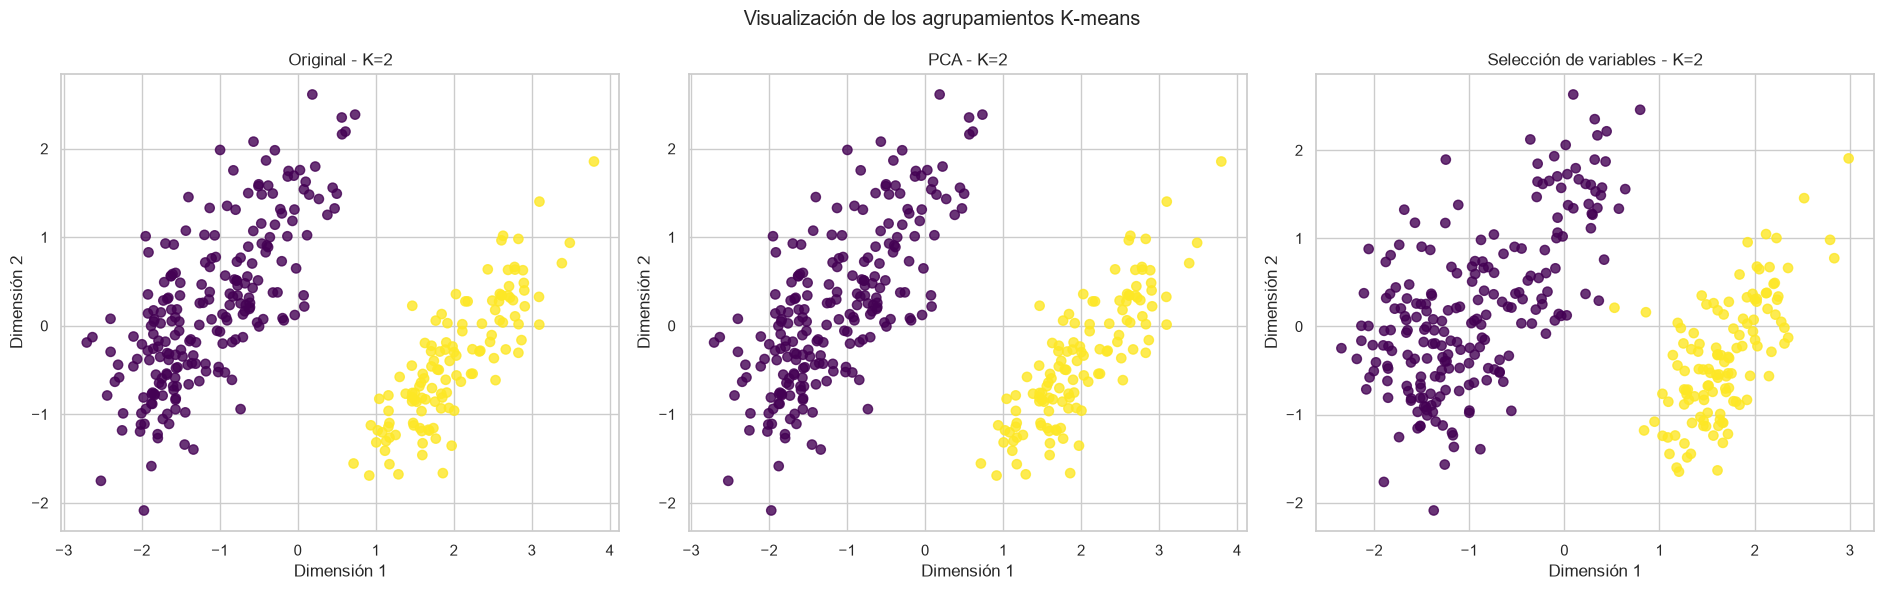

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (nombre, datos) in zip(
    axes,
    conjuntos_datos.items()
):

    mejor_k = int(
        df_resultados[
            df_resultados['Enfoque'] == nombre
        ]['Silhouette Score'].idxmax()
    )

    fila = df_resultados.loc[mejor_k]
    k = int(fila['K'])

    modelo = modelos_kmeans[nombre][k]

    etiquetas = modelo.labels_

    if nombre == 'PCA':
        coordenadas = datos[['PC1', 'PC2']].values

    else:
        coordenadas = PCA(
            n_components=2
        ).fit_transform(datos)

    ax.scatter(
        coordenadas[:, 0],
        coordenadas[:, 1],
        c=etiquetas,
        cmap='viridis',
        s=45,
        alpha=0.8
    )

    ax.set_title(f'{nombre} - K={k}')
    ax.set_xlabel('Dimensión 1')
    ax.set_ylabel('Dimensión 2')

plt.suptitle('Visualización de los agrupamientos K-means')
plt.tight_layout()
plt.show()

#### Comparación de los agrupamientos con las especies
Aunque el algoritmo K-means no utiliza etiquetas previamente conocidas, el dataset contiene información sobre las especies de los pingüinos.

Por esta razón, se realizará una comparación posterior entre los grupos encontrados por el algoritmo y las especies originales. Esta evaluación permitirá observar si los agrupamientos identificados mediante características físicas presentan correspondencia con las especies conocidas.

Se utilizarán las etiquetas de especie exclusivamente para evaluar los resultados, sin intervenir en el entrenamiento del modelo.

In [21]:
from sklearn.metrics import adjusted_rand_score

especies = df.loc[
    df_analisis.index, 'species'
]

comparacion_especies = []

for nombre, modelos in modelos_kmeans.items():

    mejor_fila = df_resultados[
        df_resultados['Enfoque'] == nombre
    ].loc[
        df_resultados[
            df_resultados['Enfoque'] == nombre
        ]['Silhouette Score'].idxmax()
    ]

    k = int(mejor_fila['K'])

    etiquetas = modelos[k].labels_

    ari = adjusted_rand_score(
        especies,
        etiquetas
    )

    comparacion_especies.append({
        'Enfoque': nombre,
        'K': k,
        'Silhouette Score': mejor_fila['Silhouette Score'],
        'Adjusted Rand Index': ari
    })

df_comparacion_especies = pd.DataFrame(
    comparacion_especies
)

display(df_comparacion_especies.round(4))

,Enfoque,K,Silhouette Score,Adjusted Rand Index
0,Original,2,0.5315,0.6551
1,PCA,2,0.6119,0.6551
2,Selección de variables,2,0.5192,0.6535


El Adjusted Rand Index (ARI) permite comparar los agrupamientos obtenidos por K-means con las especies originales.

Esta métrica toma valores cercanos a 1 cuando existe una alta correspondencia entre ambas clasificaciones, valores cercanos a 0 cuando la coincidencia es similar a la esperada por azar y valores negativos cuando la correspondencia es menor.

Esta evaluación complementaria permitirá determinar si los agrupamientos identificados estadísticamente representan diferencias relevantes entre las especies.

#### Conclusiones 
En esta última sección se presentan las principales conclusiones del experimento de aprendizaje no supervisado desarrollado con el dataset Palmer Penguins.

El análisis permitió explorar tres enfoques diferentes: el uso de las variables originales, la reducción de dimensionalidad mediante PCA y la selección de variables a partir de la matriz de correlación.

La comparación de los resultados obtenidos mediante K-means, el método del codo y el coeficiente Silhouette permitirá determinar cuál de los enfoques presenta mejores condiciones para identificar agrupamientos dentro del conjunto de datos.

Finalmente, se considerará la correspondencia entre los grupos encontrados y las especies conocidas mediante el Adjusted Rand Index, con el propósito de complementar la evaluación estadística con una interpretación de los resultados.